# Workshop 7: Detection of Outliers

Completed implementations of the four tutorials listed in `DSWKSP7_sam.pdf`. Random seeds are fixed where supported, and the external housing dataset is stored locally.

## Original tutorial links

1. [Uni/Multivariate Outlier Detection](https://www.kaggle.com/kevinarvai/outlier-detection-practice-uni-multivariate)
2. [4 Automatic Outlier Detection Algorithms in Python](https://machinelearningmastery.com/model-based-outlier-detection-and-removal-in-python/)
3. [One-Class SVM](https://www.datatechnotes.com/2020/04/anomaly-detection-with-one-class-svm.html)
4. [More on Isolation Forest and One-Class SVM](https://machinelearningmastery.com/one-class-classification-algorithms/)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

DATA_DIR = Path("Lab7") if Path("Lab7").is_dir() else Path(".")
print(f"scikit-learn {sklearn.__version__}")
print(f"Data directory: {DATA_DIR.resolve()}")

scikit-learn 1.9.1
Data directory: /Users/shuokuro/Documents/Github/DIT5412-Data-Science/Lab7


## 1. Uni/Multivariate Outlier Detection

[Original Kaggle notebook](https://www.kaggle.com/code/kevinarvai/outlier-detection-practice-uni-multivariate/notebook). Kaggle exposes the notebook metadata but requires a browser check before showing its code, so the following is an equivalent implementation rather than an exact copy. The univariate methods also follow this [accessible statistical-outlier tutorial](https://machinelearningmastery.com/how-to-use-statistics-to-identify-outliers-in-data/).

Univariate detection examines one variable at a time using Z-scores or interquartile-range fences. Multivariate Mahalanobis distance accounts for feature covariance and therefore detects unusual combinations of values.

Mean=50.049; standard deviation=4.994
Z-score outliers (|z| > 3): 29
IQR fences: [36.675, 63.370]
IQR outliers: 81


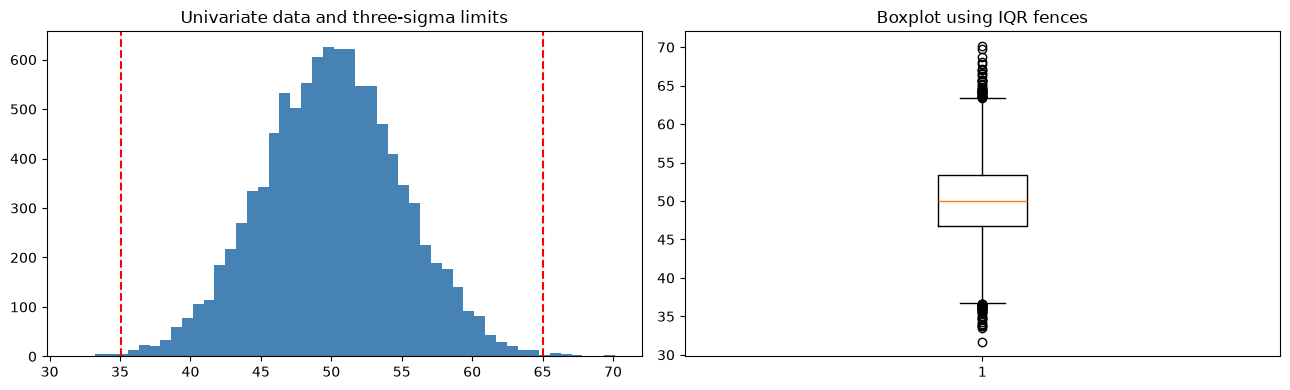

In [2]:
rng_uni = np.random.RandomState(1)
univariate_data = 5 * rng_uni.randn(10_000) + 50

data_mean = univariate_data.mean()
data_std = univariate_data.std()
z_scores = (univariate_data - data_mean) / data_std
z_outlier_mask = np.abs(z_scores) > 3

q25, q75 = np.percentile(univariate_data, [25, 75])
iqr = q75 - q25
iqr_lower = q25 - 1.5 * iqr
iqr_upper = q75 + 1.5 * iqr
iqr_outlier_mask = (univariate_data < iqr_lower) | (univariate_data > iqr_upper)

print(f"Mean={data_mean:.3f}; standard deviation={data_std:.3f}")
print(f"Z-score outliers (|z| > 3): {z_outlier_mask.sum()}")
print(f"IQR fences: [{iqr_lower:.3f}, {iqr_upper:.3f}]")
print(f"IQR outliers: {iqr_outlier_mask.sum()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(univariate_data, bins=50, color="steelblue")
axes[0].axvline(data_mean - 3 * data_std, color="red", linestyle="--")
axes[0].axvline(data_mean + 3 * data_std, color="red", linestyle="--")
axes[0].set_title("Univariate data and three-sigma limits")
axes[1].boxplot(univariate_data)
axes[1].set_title("Boxplot using IQR fences")
plt.tight_layout()
plt.show()

97.5% chi-square threshold: 7.378
Classical Mahalanobis outliers: 6
Robust MCD Mahalanobis outliers: 13


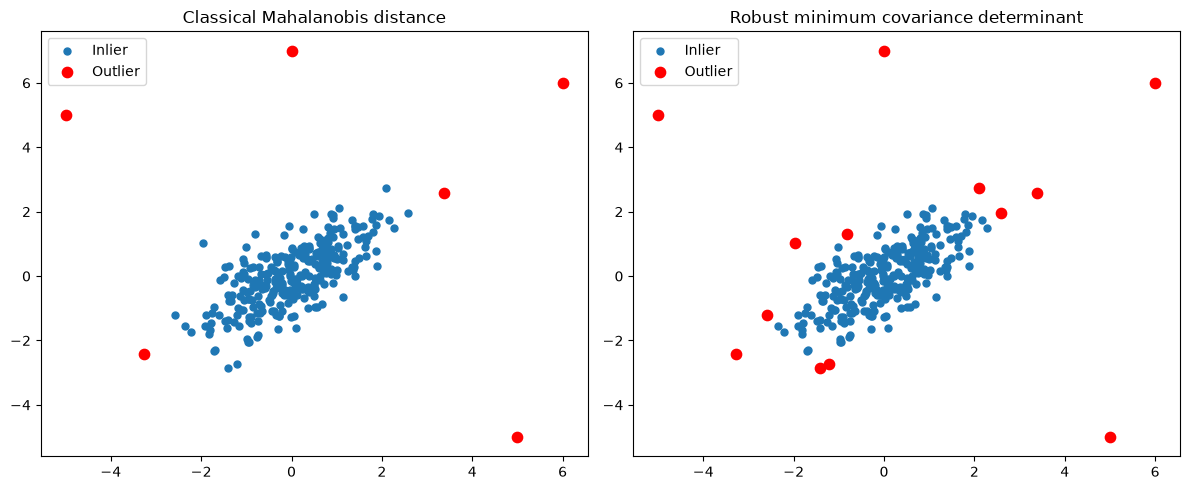

In [3]:
from scipy.stats import chi2
from sklearn.covariance import MinCovDet

rng_multi = np.random.RandomState(42)
X_normal = rng_multi.multivariate_normal(
    mean=[0, 0], cov=[[1, 0.7], [0.7, 1]], size=300
)
X_multi = np.vstack([
    X_normal,
    np.array([[6, 6], [-5, 5], [5, -5], [0, 7]]),
])

center = X_multi.mean(axis=0)
covariance = np.cov(X_multi, rowvar=False)
inverse_covariance = np.linalg.inv(covariance)
delta = X_multi - center
classical_distance_squared = np.einsum(
    "ij,jk,ik->i", delta, inverse_covariance, delta
)
distance_threshold = chi2.ppf(0.975, df=X_multi.shape[1])
classical_outliers = classical_distance_squared > distance_threshold

robust_covariance = MinCovDet(random_state=42).fit(X_multi)
robust_distance_squared = robust_covariance.mahalanobis(X_multi)
robust_outliers = robust_distance_squared > distance_threshold

print(f"97.5% chi-square threshold: {distance_threshold:.3f}")
print(f"Classical Mahalanobis outliers: {classical_outliers.sum()}")
print(f"Robust MCD Mahalanobis outliers: {robust_outliers.sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, mask, title in [
    (axes[0], classical_outliers, "Classical Mahalanobis distance"),
    (axes[1], robust_outliers, "Robust minimum covariance determinant"),
]:
    ax.scatter(X_multi[~mask, 0], X_multi[~mask, 1], s=25, label="Inlier")
    ax.scatter(X_multi[mask, 0], X_multi[mask, 1], s=55, c="red", label="Outlier")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

## 2. Four Automatic Outlier Detection Algorithms

[Original tutorial](https://machinelearningmastery.com/model-based-outlier-detection-and-removal-in-python/). A linear regression baseline is established on the housing dataset. Isolation Forest, Elliptic Envelope (Minimum Covariance Determinant), Local Outlier Factor, and One-Class SVM then remove outliers **from the training set only**, avoiding test-set leakage.

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

housing = pd.read_csv(DATA_DIR / "housing.csv", header=None)
housing_data = housing.to_numpy()
X_housing = housing_data[:, :-1]
y_housing = housing_data[:, -1]
X_house_train, X_house_test, y_house_train, y_house_test = train_test_split(
    X_housing, y_housing, test_size=0.33, random_state=1
)

baseline_model = LinearRegression().fit(X_house_train, y_house_train)
baseline_predictions = baseline_model.predict(X_house_test)
baseline_mae = mean_absolute_error(y_house_test, baseline_predictions)

print(f"Full dataset: X={X_housing.shape}, y={y_housing.shape}")
print(f"Training set: X={X_house_train.shape}; test set: X={X_house_test.shape}")
print(f"Baseline MAE: {baseline_mae:.3f}")

Full dataset: X=(506, 13), y=(506,)
Training set: X=(339, 13); test set: X=(167, 13)
Baseline MAE: 3.417


,method,training_rows,outliers_removed,mae
0,Baseline (no removal),339,0,3.417
1,Isolation Forest,305,34,3.196
2,Elliptic Envelope,335,4,3.435
3,Local Outlier Factor,305,34,3.356
4,One-Class SVM,336,3,3.431


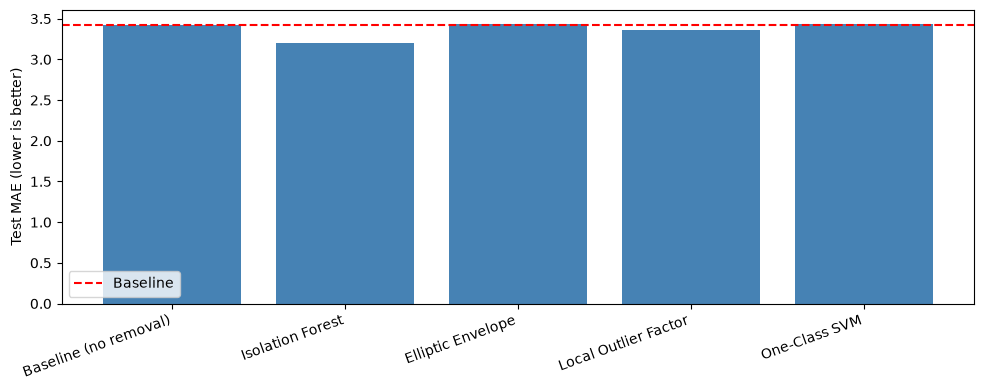

In [5]:
from sklearn.covariance import EllipticEnvelope
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

detectors = {
    "Isolation Forest": IsolationForest(contamination=0.1, random_state=42),
    "Elliptic Envelope": EllipticEnvelope(contamination=0.01),
    "Local Outlier Factor": LocalOutlierFactor(),
    "One-Class SVM": OneClassSVM(nu=0.01),
}

removal_results = [{
    "method": "Baseline (no removal)",
    "training_rows": len(X_house_train),
    "outliers_removed": 0,
    "mae": baseline_mae,
}]

for name, detector in detectors.items():
    outlier_labels = detector.fit_predict(X_house_train)
    inlier_mask = outlier_labels != -1
    X_filtered = X_house_train[inlier_mask]
    y_filtered = y_house_train[inlier_mask]
    model = LinearRegression().fit(X_filtered, y_filtered)
    predictions = model.predict(X_house_test)
    removal_results.append({
        "method": name,
        "training_rows": len(X_filtered),
        "outliers_removed": int((~inlier_mask).sum()),
        "mae": mean_absolute_error(y_house_test, predictions),
    })

removal_results = pd.DataFrame(removal_results)
display(removal_results.round({"mae": 3}))

plt.figure(figsize=(10, 4))
plt.bar(removal_results["method"], removal_results["mae"], color="steelblue")
plt.axhline(baseline_mae, color="red", linestyle="--", label="Baseline")
plt.ylabel("Test MAE (lower is better)")
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

## 3. One-Class SVM

[Original tutorial](https://www.datatechnotes.com/2020/04/anomaly-detection-with-one-class-svm.html). One-Class SVM learns the support of the normal data distribution. Anomalies are identified in two ways: labels returned by `predict()` and a lower-tail quantile of `score_samples()`.

Anomalies from predicted labels: 5
Three-percent score threshold: 3.9944
Anomalies from score threshold: 6


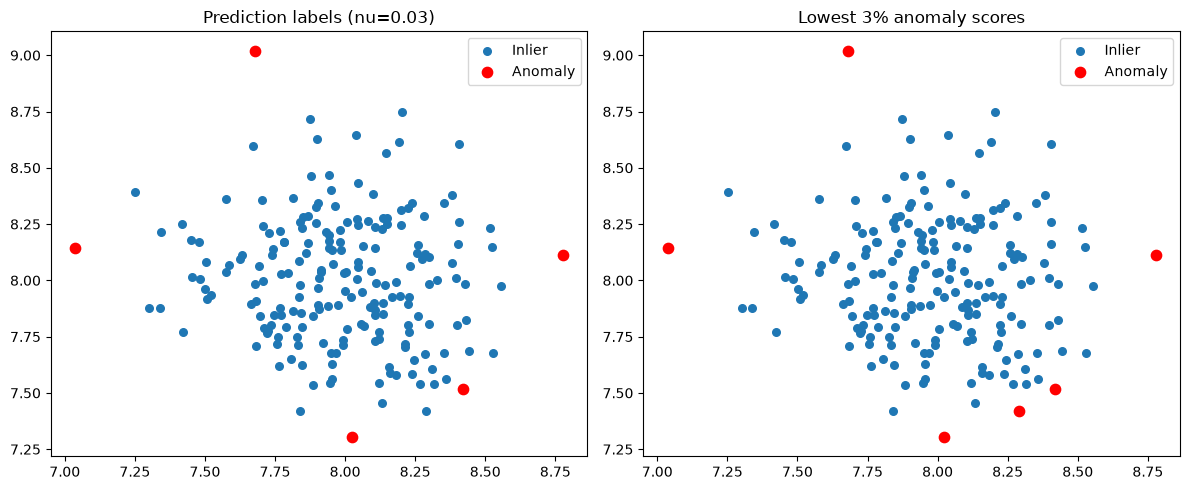

In [6]:
from sklearn.datasets import make_blobs

X_one_class, _ = make_blobs(
    n_samples=200,
    centers=1,
    cluster_std=0.3,
    center_box=(8, 8),
    random_state=np.random.RandomState(13),
)

ocsvm_labels = OneClassSVM(kernel="rbf", gamma=0.001, nu=0.03)
predicted_labels = ocsvm_labels.fit_predict(X_one_class)
label_anomalies = X_one_class[predicted_labels == -1]

ocsvm_scores = OneClassSVM(kernel="rbf", gamma=0.001, nu=0.02)
ocsvm_scores.fit(X_one_class)
anomaly_scores = ocsvm_scores.score_samples(X_one_class)
score_threshold = np.quantile(anomaly_scores, 0.03)
score_anomalies = X_one_class[anomaly_scores <= score_threshold]

print(f"Anomalies from predicted labels: {len(label_anomalies)}")
print(f"Three-percent score threshold: {score_threshold:.4f}")
print(f"Anomalies from score threshold: {len(score_anomalies)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, anomalies, title in [
    (axes[0], label_anomalies, "Prediction labels (nu=0.03)"),
    (axes[1], score_anomalies, "Lowest 3% anomaly scores"),
]:
    ax.scatter(X_one_class[:, 0], X_one_class[:, 1], s=30, label="Inlier")
    ax.scatter(anomalies[:, 0], anomalies[:, 1], c="red", s=55, label="Anomaly")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

## 4. More on Isolation Forest and One-Class SVM

[Original tutorial](https://machinelearningmastery.com/one-class-classification-algorithms/). One-class classifiers can be applied to severely imbalanced binary data by fitting only the majority class. The minority class is treated as anomalous. One-Class SVM, Isolation Forest, Elliptic Envelope, and Local Outlier Factor are evaluated using minority-class F1 scores.

Full class distribution: Counter({np.int64(0): 9990, np.int64(1): 10})
Majority-only training rows: 4995
Test class distribution: Counter({np.int64(0): 4995, np.int64(1): 5})


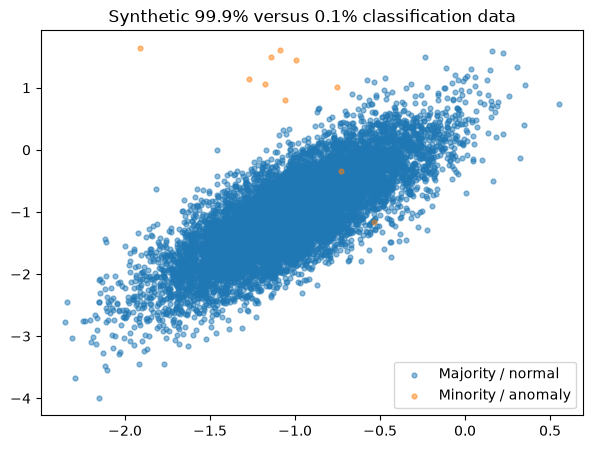

In [7]:
from collections import Counter
from sklearn.datasets import make_classification

X_imbalanced, y_imbalanced = make_classification(
    n_samples=10_000,
    n_features=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.999],
    flip_y=0,
    random_state=4,
)
X_occ_train, X_occ_test, y_occ_train, y_occ_test = train_test_split(
    X_imbalanced,
    y_imbalanced,
    test_size=0.5,
    random_state=2,
    stratify=y_imbalanced,
)
X_normal_train = X_occ_train[y_occ_train == 0]
y_occ_test_transformed = np.where(y_occ_test == 0, 1, -1)

print(f"Full class distribution: {Counter(y_imbalanced)}")
print(f"Majority-only training rows: {len(X_normal_train)}")
print(f"Test class distribution: {Counter(y_occ_test)}")

plt.figure(figsize=(7, 5))
for class_label, class_name in [(0, "Majority / normal"), (1, "Minority / anomaly")]:
    rows = y_imbalanced == class_label
    plt.scatter(
        X_imbalanced[rows, 0], X_imbalanced[rows, 1],
        s=12, alpha=0.5, label=class_name,
    )
plt.title("Synthetic 99.9% versus 0.1% classification data")
plt.legend()
plt.show()

,method,predicted_outliers,minority_f1
0,One-Class SVM,60,0.123
1,Isolation Forest,33,0.000
2,Elliptic Envelope,46,0.157
3,Local Outlier Factor,53,0.138


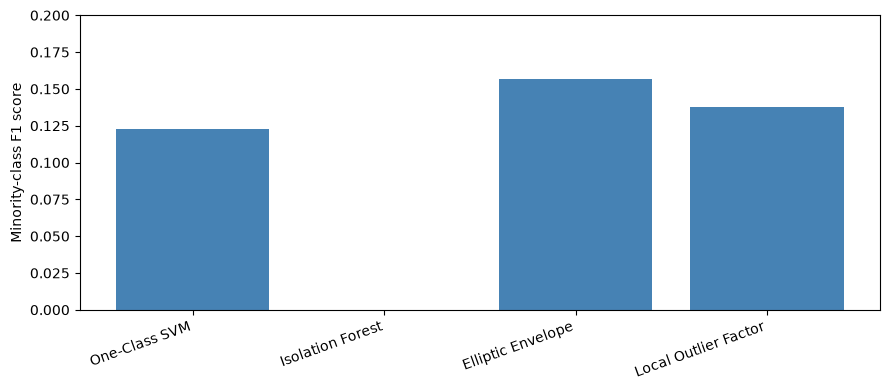

In [8]:
from sklearn.metrics import f1_score

one_class_models = {
    "One-Class SVM": OneClassSVM(gamma="scale", nu=0.01),
    "Isolation Forest": IsolationForest(contamination=0.01, random_state=42),
    "Elliptic Envelope": EllipticEnvelope(contamination=0.01),
}

occ_results = []
for name, model in one_class_models.items():
    model.fit(X_normal_train)
    predictions = model.predict(X_occ_test)
    occ_results.append({
        "method": name,
        "predicted_outliers": int((predictions == -1).sum()),
        "minority_f1": f1_score(y_occ_test_transformed, predictions, pos_label=-1),
    })

lof = LocalOutlierFactor(contamination=0.01)
composite_data = np.vstack((X_normal_train, X_occ_test))
lof_predictions = lof.fit_predict(composite_data)[len(X_normal_train):]
occ_results.append({
    "method": "Local Outlier Factor",
    "predicted_outliers": int((lof_predictions == -1).sum()),
    "minority_f1": f1_score(y_occ_test_transformed, lof_predictions, pos_label=-1),
})

occ_results = pd.DataFrame(occ_results)
display(occ_results.round({"minority_f1": 3}))

plt.figure(figsize=(9, 4))
plt.bar(occ_results["method"], occ_results["minority_f1"], color="steelblue")
plt.ylabel("Minority-class F1 score")
plt.ylim(0, max(0.2, occ_results["minority_f1"].max() * 1.15))
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()